# Does raw fee volatility penalize healthy growth?

This comparison separates **total weekly fee variability**, **fluctuations around a linear trend**, and **weekly downside**. It keeps the existing revenue-only top 100 and expected return unchanged. No portfolio is optimized.

The main comparison uses the latest **26 complete Monday–Sunday weeks** at eight November 2021–June 2022 cutoffs. The same five February–June cutoffs compare 26 weeks, 52 weeks and all available history. September 2022 is a descriptive snapshot without a complete future quarter.

Expected return remains historical mean monthly gross fees. Gross fees equal sales × take-rate percentage / 100. They exclude credit/fraud losses, funding and operating expenses, and are not settlement cash flow.

## Freeze definitions before looking at outcomes

For one merchant or the **sum of fees from a fixed portfolio**, let weekly fees be $F_w$ and fit a line using only the historical window:

$$F_w = a + b(w-\bar w) + e_w.$$

| Measure | Calculation | Interpretation |
|---|---|---|
| Raw SD | $\sqrt{\sum(F_w-\bar F)^2/(n-1)}$ | All observed fee variability, including trend |
| Residual SD | $\sqrt{\sum e_w^2/(n-2)}$ | Fluctuations around the fitted line, correcting for two fitted parameters |
| Downside below mean | $\sqrt{\frac1n\sum\max(\bar F-F_w,0)^2}$ | Shortfall below the historical average; use **all** weeks in the denominator |
| Downside below trend (sensitivity) | $\sqrt{\frac1n\sum\max(-e_w,0)^2}$ | Shortfall below the fitted historical path |

The exact descriptive decomposition is **raw variance = trend variance + residual variance with denominator n−1**. This differs slightly from the degrees-of-freedom-corrected residual SD used as a risk estimate. Fitting a line cannot increase residual sum of squares. The n−2 correction can nevertheless make residual SD slightly larger than raw SD when the fitted trend explains very little. Neither result establishes superior forecasting.

Always retain the sign and size of the trend: perfectly smooth growth and decline both have zero residual variability. Downside below the historical average can also count early weeks of healthy growth as shortfalls.

For later weeks, freeze the historical mean and extrapolate the historical line (floor negative forecasts at zero). Fit a new line inside the future quarter **only to describe the realized residual-variation outcome**, never to construct historical features. Also measure error against the **frozen** historical line so failed trend continuation remains visible.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import StrMethodFormatter
from IPython.display import display, Markdown

here = Path.cwd()
ROOT = next(p for p in [here, *here.parents] if (p / 'code/scripts/cash_flow_risk_comparison.py').exists())
sys.path.insert(0, str(ROOT / 'code/scripts'))
import cash_flow_risk_comparison as comparison

features, portfolios, summary = comparison.run()
OUT = comparison.OUT
plots = OUT / 'plots'
plots.mkdir(exist_ok=True)
primary = portfolios.loc[portfolios.window.eq('26w') & portfolios.status.eq('observed')].sort_values('as_of')
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})

Estimating risk definitions at 2021-11-30


Estimating risk definitions at 2021-12-31


Estimating risk definitions at 2022-01-31


Estimating risk definitions at 2022-02-28


Estimating risk definitions at 2022-03-31


Estimating risk definitions at 2022-04-30


Estimating risk definitions at 2022-05-31


Estimating risk definitions at 2022-06-30


Estimating risk definitions at 2022-09-30


       comparison window            measure                target  origins  mean_estimate  mean_actual  mean_absolute_error  mean_signed_error  underestimate_count
primary_26w_eight    26w      downside_mean  future_downside_mean        8      47873.069    37250.353            40259.347          10622.716                    3
primary_26w_eight    26w     downside_trend future_downside_trend        8      42727.657    77486.466            87197.202         -34758.810                    4
primary_26w_eight    26w             raw_sd         future_raw_sd        8      92110.515    31179.731            65433.187          60930.784                    1
primary_26w_eight    26w      raw_shrunk_sd         future_raw_sd        8      68407.659    31179.731            50931.179          37227.928                    1
primary_26w_eight    26w        residual_sd    future_residual_sd        8      80518.646    19396.671            61776.603          61121.975                    1
primary_26w_eigh

## Sanity checks with known patterns

These toy histories isolate what each definition does. Steady growth and steady decline have identical means, raw SD and below-mean downside, but opposite slopes. Both have zero detrended risk. A risk measure that removes growth therefore needs a separate check for deterioration.

In [2]:
display(comparison.toy_scenarios()[['scenario', 'weekly_mean', 'trend_slope_per_week', 'raw_sd', 'residual_sd', 'downside_mean', 'downside_trend']].round(3))

,scenario,weekly_mean,trend_slope_per_week,raw_sd,residual_sd,downside_mean,downside_trend
0,constant,162.5,0.000,0.000,0.000,0.000,0.000
1,steady_growth,162.5,5.000,38.243,0.000,26.517,0.000
2,steady_decline,162.5,-5.000,38.243,0.000,26.517,0.000
3,alternating,162.5,0.267,30.594,31.156,21.213,21.166
4,midpoint_drop,162.5,-7.222,63.738,32.454,44.194,22.048


## How much of the fixed portfolio's historical variation is trend?

The percentage below is the share of **variance**, not the percentage reduction in standard deviation. A positive trend is evidence of historical growth, not proof that it is predictable or sustainable. Calendar and nonlinear effects remain in the residuals.

,as_of,history_weeks,trend_slope_per_week,trend_variance_share,raw_sd,residual_sd,downside_mean,downside_trend,raw_alpha,residual_alpha
0,2021-11-30,26,6826.154,0.430,79603.474,61329.245,28657.716,25741.809,0.722,0.721
2,2021-12-31,26,9362.675,0.561,95607.542,64652.198,44544.820,31772.873,0.457,0.615
4,2022-01-31,26,1823.775,0.018,103224.849,104387.047,54227.514,57768.843,0.407,0.398
6,2022-02-28,26,-3204.046,0.051,108741.525,108128.797,58617.745,52233.458,0.375,0.390
9,2022-03-31,26,-6058.065,0.177,110027.492,101853.091,59299.473,53485.130,0.367,0.393
12,2022-04-30,26,-7597.643,0.275,110802.409,96286.840,58392.072,57627.408,0.367,0.378
15,2022-05-31,26,-2743.887,0.063,83407.317,82388.428,46030.539,51568.096,0.432,0.382
18,2022-06-30,26,4998.347,0.707,45469.515,25123.519,33214.675,11623.638,0.639,0.854


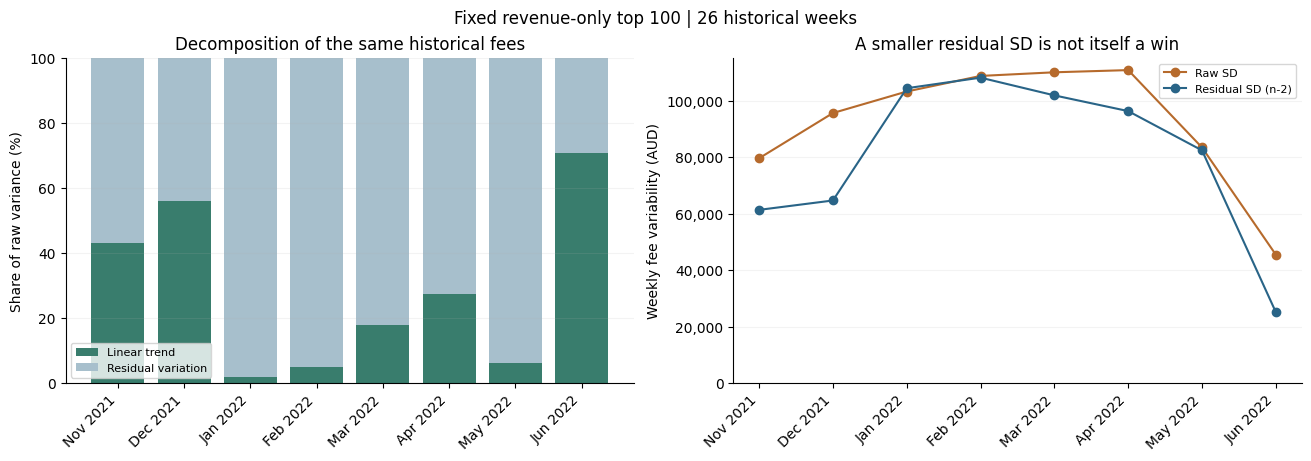

In [3]:
columns = ['as_of', 'history_weeks', 'trend_slope_per_week', 'trend_variance_share',
           'raw_sd', 'residual_sd', 'downside_mean', 'downside_trend', 'raw_alpha', 'residual_alpha']
display(primary[columns].round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout='constrained')
x = np.arange(len(primary))
share = primary.trend_variance_share.to_numpy()*100
axes[0].bar(x, share, color='#397d6d', label='Linear trend')
axes[0].bar(x, 100-share, bottom=share, color='#a7bfcc', label='Residual variation')
axes[0].set(ylabel='Share of raw variance (%)', ylim=(0, 100), title='Decomposition of the same historical fees')
axes[0].legend(loc='lower left', fontsize=8)
axes[1].plot(x, primary.raw_sd, color='#b66a2c', marker='o', label='Raw SD')
axes[1].plot(x, primary.residual_sd, color='#296487', marker='o', label='Residual SD (n-2)')
axes[1].set(ylabel='Weekly fee variability (AUD)', ylim=(0, None), title='A smaller residual SD is not itself a win')
axes[1].yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
axes[1].legend(fontsize=8)
for ax in axes:
    ax.set_xticks(x, primary.as_of.dt.strftime('%b %Y'), rotation=45, ha='right')
    ax.grid(axis='y', alpha=.15)
fig.suptitle('Fixed revenue-only top 100 | 26 historical weeks')
fig.savefig(plots / 'variance_decomposition.png', dpi=160)
plt.show()

## Later outcomes: different measures answer different questions

The error table compares each estimator with its corresponding later statistic. **Do not compare MAEs across different targets to declare a winning risk definition.** Raw and shrunk estimates of the *same* target can be compared. Later statistics use only 11–13 complete weeks and are themselves noisy.

The frozen-line error is particularly important: a new line fitted to the future quarter can describe small fluctuations even when the old trend forecast fails badly.

In [4]:
display(summary.loc[summary.comparison.eq('primary_26w_eight'),
    ['measure', 'target', 'origins', 'mean_estimate', 'mean_actual', 'mean_absolute_error', 'mean_signed_error', 'underestimate_count']].round(2))
display(primary[['as_of', 'future_weeks', 'future_raw_sd', 'future_residual_sd', 'future_trend_error_rms',
                 'future_downside_mean', 'future_downside_trend']].round(2))

,measure,target,origins,mean_estimate,mean_actual,mean_absolute_error,mean_signed_error,underestimate_count
0,downside_mean,future_downside_mean,8,47873.07,37250.35,40259.35,10622.72,3
1,downside_trend,future_downside_trend,8,42727.66,77486.47,87197.20,-34758.81,4
2,raw_sd,future_raw_sd,8,92110.52,31179.73,65433.19,60930.78,1
3,raw_shrunk_sd,future_raw_sd,8,68407.66,31179.73,50931.18,37227.93,1
4,residual_sd,future_residual_sd,8,80518.65,19396.67,61776.60,61121.97,1
5,residual_shrunk_sd,future_residual_sd,8,58982.34,19396.67,48222.73,39585.67,2


,as_of,future_weeks,future_raw_sd,future_residual_sd,future_trend_error_rms,future_downside_mean,future_downside_trend
0,2021-11-30,12.0,97613.09,63947.76,196962.85,71206.56,196187.62
2,2021-12-31,12.0,29488.54,13284.77,287894.74,104202.43,287894.74
4,2022-01-31,11.0,28312.35,14126.03,103155.43,70567.58,103155.43
6,2022-02-28,12.0,23419.32,12888.64,51209.68,32701.91,5160.52
9,2022-03-31,12.0,19142.79,11046.66,122253.71,17020.80,0.00
12,2022-04-30,13.0,13537.49,10648.15,173600.19,2303.54,0.00
15,2022-05-31,12.0,18810.70,14715.35,103984.74,0.00,0.00
18,2022-06-30,12.0,19113.58,14516.00,27575.09,0.00,27493.42


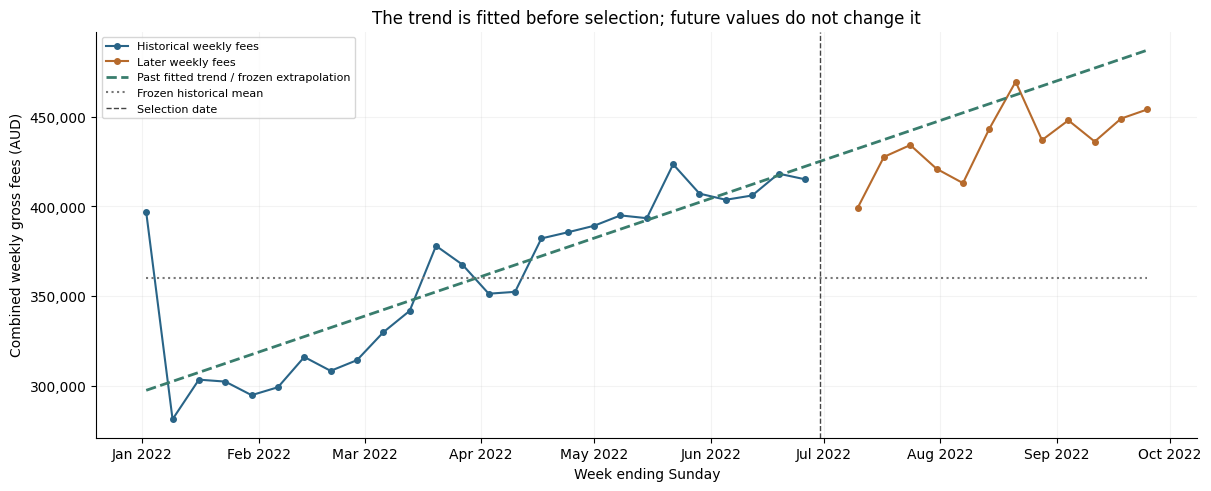

In [5]:
weeks = pd.read_parquet(OUT / 'portfolio_weekly_fees.parquet')
as_of = pd.Timestamp('2022-06-30')  # Same illustrative cutoff as the earlier cash-flow notebook.
view = weeks.loc[weeks.as_of.eq(as_of) & weeks.window.eq('26w')].sort_values('week_end')
fig, ax = plt.subplots(figsize=(12, 4.8), layout='constrained')
for phase, color, label in [('history', '#296487', 'Historical weekly fees'), ('future', '#b66a2c', 'Later weekly fees')]:
    part = view.loc[view.phase.eq(phase)]
    ax.plot(part.week_end, part.gross_fees, 'o-', color=color, markersize=4, label=label)
ax.plot(view.week_end, view.reference_trend, '--', color='#397d6d', linewidth=2,
        label='Past fitted trend / frozen extrapolation')
ax.plot(view.week_end, view.reference_mean, ':', color='#777777', label='Frozen historical mean')
ax.axvline(as_of, color='#444444', linestyle='--', linewidth=1, label='Selection date')
ax.set(title='The trend is fitted before selection; future values do not change it',
       xlabel='Week ending Sunday', ylabel='Combined weekly gross fees (AUD)')
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
ax.grid(alpha=.15)
ax.legend(fontsize=8, loc='best')
fig.savefig(plots / 'frozen_trend_and_downside.png', dpi=160)
plt.show()

## Merchant-level check against one common later outcome

For this diagnostic, divide each historical risk measure by that merchant's historical mean weekly fees. Compare its rank with **later downside below the frozen historical mean, divided by the same historical mean**. This reduces the obvious merchant-size effect; shared denominators can still affect associations.

Report equal-origin Spearman correlations descriptively. Do not treat thousands of merchants or overlapping origins as independent macroeconomic replications. A separate negative-trend indicator checks whether steady deterioration carries information that residual variability discards.

measure,downside_mean,downside_trend,negative_trend,raw_sd,residual_sd
as_of,,,,,
2021-11-30,0.909,0.907,0.368,0.901,0.903
2021-12-31,0.899,0.899,0.335,0.892,0.895
2022-01-31,0.911,0.909,0.299,0.903,0.902
2022-02-28,0.926,0.927,0.002,0.918,0.917
2022-03-31,0.930,0.929,-0.013,0.921,0.921
2022-04-30,0.935,0.932,0.019,0.926,0.929
2022-05-31,0.939,0.936,0.034,0.934,0.934
2022-06-30,0.940,0.942,0.389,0.939,0.940


,mean,min,max
measure,,,
downside_mean,0.924,0.899,0.940
downside_trend,0.923,0.899,0.942
negative_trend,0.179,-0.013,0.389
raw_sd,0.917,0.892,0.939
residual_sd,0.918,0.895,0.940


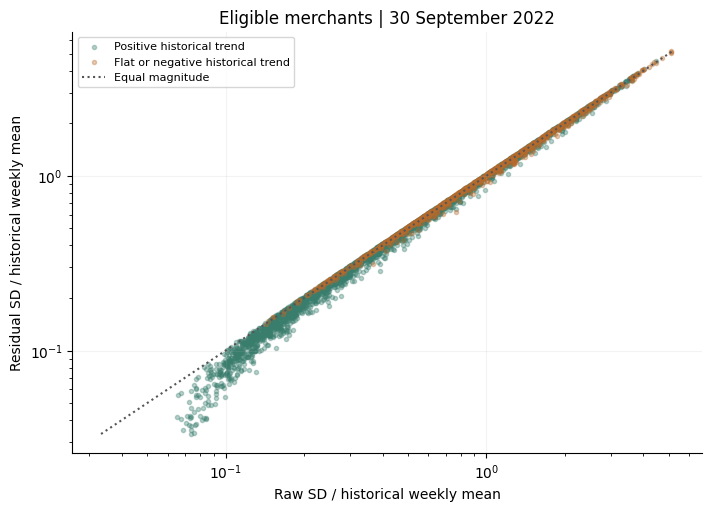

0 eligible merchants omitted from the log plot for zero-valued measures.


In [6]:
associations = pd.read_parquet(OUT / 'merchant_rank_associations.parquet')
display(associations.loc[associations.window.eq('26w')].pivot(index='as_of', columns='measure', values='spearman').round(3))
display(associations.loc[associations.window.eq('26w')].groupby('measure').spearman.agg(['mean', 'min', 'max']).round(3))
latest = features.loc[features.as_of.eq(pd.Timestamp('2022-09-30')) & features.window.eq('26w') & features.eligible].copy()
plottable = latest.loc[latest.raw_sd.gt(0) & latest.residual_sd.gt(0) & latest.weekly_mean.gt(0)]
fig, ax = plt.subplots(figsize=(7, 5), layout='constrained')
for up, color, label in [(True, '#397d6d', 'Positive historical trend'), (False, '#b66a2c', 'Flat or negative historical trend')]:
    part = plottable.loc[plottable.trend_slope_per_week.gt(0).eq(up)]
    ax.scatter(part.raw_sd/part.weekly_mean, part.residual_sd/part.weekly_mean, s=9, alpha=.35, color=color, label=label)
lo = min((plottable.raw_sd/plottable.weekly_mean).min(), (plottable.residual_sd/plottable.weekly_mean).min())
hi = max((plottable.raw_sd/plottable.weekly_mean).max(), (plottable.residual_sd/plottable.weekly_mean).max())
ax.plot([lo, hi], [lo, hi], ':', color='#555555', label='Equal magnitude')
ax.set(xscale='log', yscale='log', xlabel='Raw SD / historical weekly mean', ylabel='Residual SD / historical weekly mean',
       title='Eligible merchants | 30 September 2022')
ax.legend(fontsize=8)
ax.grid(alpha=.15)
fig.savefig(plots / 'merchant_relative_risk.png', dpi=160)
plt.show()
print(f'{len(latest)-len(plottable)} eligible merchants omitted from the log plot for zero-valued measures.')

## Sensitivity, covariance and acceptance checks

All three lookbacks use the same five cutoffs below. Raw covariance is unchanged. Residual covariance is computed from aligned merchant residuals, with n−2 degrees of freedom; its portfolio variance equals the variance of aggregate residual fees. The optional Ledoit–Wolf estimate shrinks residual correlations while preserving residual variances. It is not a reduction in realized risk.

Saved residual factors are ABN-indexed and compatible with `cash_flow_variability.load_covariance`, `covariance_submatrix`, and `portfolio_volatility`. Do **not** use covariance of individually clipped shortfalls as an exact portfolio downside formula: gains at one merchant can offset a shortfall at another.

Source signatures, daily-panel checksum, calendar coverage and daily/monthly/weekly sales and order counts are rechecked. Future daily transactions are perturbed at every scored cutoff; earlier measures, shrinkage coefficients and selections must stay identical. Historical estimates and references are saved before scoring future outcomes. Reruns must reproduce the saved digests.

In [7]:
display(summary.loc[summary.comparison.eq('sensitivity_common_five'),
    ['window', 'measure', 'target', 'origins', 'mean_absolute_error', 'mean_signed_error']].round(2))
display(pd.read_parquet(OUT / 'nonoverlapping_schedules.parquet').round(2))
display(portfolios.loc[portfolios.as_of.eq(pd.Timestamp('2022-09-30')),
    ['window', 'history_weeks', 'trend_slope_per_week', 'trend_variance_share', 'raw_sd', 'residual_sd', 'downside_mean', 'downside_trend', 'status']].round(3))
display(json.loads((OUT / 'acceptance_checks.json').read_text()))

,window,measure,target,origins,mean_absolute_error,mean_signed_error
6,26w,downside_mean,future_downside_mean,5,40705.65,40705.65
7,26w,downside_trend,future_downside_trend,5,45124.67,38776.76
8,26w,raw_sd,future_raw_sd,5,72884.88,72884.88
9,26w,raw_shrunk_sd,future_raw_sd,5,51945.30,51945.30
10,26w,residual_sd,future_residual_sd,5,69993.17,69993.17
11,26w,residual_shrunk_sd,future_residual_sd,5,52066.28,50579.18
12,52w,downside_mean,future_downside_mean,5,36278.59,36278.59
13,52w,downside_trend,future_downside_trend,5,30140.09,24067.21
14,52w,raw_sd,future_raw_sd,5,63995.09,63995.09
15,52w,raw_shrunk_sd,future_raw_sd,5,47765.20,47765.20


,comparison,window,measure,target,origins,mean_estimate,mean_actual,mean_absolute_error,mean_signed_error,underestimate_count,cutoffs
0,schedule_0,26w,downside_mean,future_downside_mean,3,44435.33,34636.16,38165.07,9799.18,1,"2021-11-30, 2022-02-28, 2022-05-31"
1,schedule_0,26w,downside_trend,future_downside_trend,3,43181.12,67116.05,89695.61,-23934.93,1,"2021-11-30, 2022-02-28, 2022-05-31"
2,schedule_0,26w,raw_sd,future_raw_sd,3,90584.11,46614.37,55976.14,43969.74,1,"2021-11-30, 2022-02-28, 2022-05-31"
3,schedule_0,26w,raw_shrunk_sd,future_raw_sd,3,64106.94,46614.37,54034.58,17492.58,1,"2021-11-30, 2022-02-28, 2022-05-31"
4,schedule_0,26w,residual_sd,future_residual_sd,3,83948.82,30517.25,55177.25,53431.57,1,"2021-11-30, 2022-02-28, 2022-05-31"
5,schedule_0,26w,residual_shrunk_sd,future_residual_sd,3,61012.07,30517.25,51048.49,30494.82,1,"2021-11-30, 2022-02-28, 2022-05-31"
6,schedule_1,26w,downside_mean,future_downside_mean,3,45686.32,40407.74,45050.32,5278.58,1,"2021-12-31, 2022-03-31, 2022-06-30"
7,schedule_1,26w,downside_trend,future_downside_trend,3,32293.88,105129.38,108492.26,-72835.50,2,"2021-12-31, 2022-03-31, 2022-06-30"
8,schedule_1,26w,raw_sd,future_raw_sd,3,83701.52,22581.64,61119.88,61119.88,0,"2021-12-31, 2022-03-31, 2022-06-30"
9,schedule_1,26w,raw_shrunk_sd,future_raw_sd,3,62183.72,22581.64,39602.09,39602.09,0,"2021-12-31, 2022-03-31, 2022-06-30"


,window,history_weeks,trend_slope_per_week,trend_variance_share,raw_sd,residual_sd,downside_mean,downside_trend,status
21,26w,26,3415.188,0.799,29216.122,13356.744,21354.539,9191.510,unavailable
22,52w,52,43.752,0.000,80189.919,80985.080,46923.511,46759.422,unavailable
23,all,82,1375.275,0.193,74563.107,67401.889,42094.681,33951.889,unavailable


{'source_signatures_and_daily_checksum': True,
 'daily_monthly_and_weekly_sales_orders_reconciled': True,
 'unique_feature_keys': True,
 'exactly_100_eligible_unique_merchants_per_cutoff': True,
 'baseline_reproductions': 9,
 'future_daily_perturbations': 21,
 'covariance_and_decomposition_checks': 24,
 'independent_daily_future_portfolios': 21,
 'references_frozen_before_outcomes': True,
 'september_unscored': True,
 'reproducible_rerun': False,
 'digests': {'features': '4d2bba53f0faf7ad4a39e3018bcb25ecdf1d72a78c501e26e4bbc86a22fab982',
  'estimates': 'bf2e6dd79067f2a7ed34c82289e6320fbd324838ce54cc9064793c5735d90916',
  'selections': '849314a7f03e756b6701638f7d1127c385b001dd9bc8c231c59edeae95ecee77',
  'outcomes': '92d6b1e6b8e5f336e68fd51f947013bdbf515a474d47e1fe96e88d74dd19681e',
  'merchant_outcomes': 'd2833c568124afbe66c62753b6c6356ca6108a43958d240a7a17020bebc2307b',
  'summary': '32fb356c5d3acdf26101006b233fb98a09ffb1ddd4e4d918473a32ec9138e866',
  'associations': '7d2c5a7a3c7c7765

## What this can and cannot establish

- At September 2022, the upward linear trend explained **79.9%** of the fixed portfolio’s 26-week variance; raw SD was **A$29,216** and residual SD **A$13,357**. This is window-dependent: the 52-week linear trend explained about **0.01%**, and the all-history trend **19.3%**.
- Raw variability can count healthy growth as risk. Removing a linear trend separates that component descriptively; it does not make the remaining risk predictably stable.
- Residual covariance is a candidate for measuring fluctuations, but slope direction and shortfalls against a frozen reference are needed to expose deterioration and trend breaks.
- Downside requires an explicit income reference. Below-mean downside is not growth-neutral; below-trend downside can hide a steady decline. Neither is observed credit loss.
- Expected return and the existing 26-week feature remain unchanged. Choosing an optimization objective requires a business interpretation and a later comparison of actual selected-portfolio revenue and risk.
- The 19-month synthetic history, overlapping evaluations and previously examined outcomes do not provide an untouched holdout or a significance claim. Assume take rates and categories were stable and available historically.

**Reproduce:** `python code/scripts/cash_flow_risk_comparison.py`  
**Validate:** `python -m pytest -p no:capture code/tests/test_cash_flow_risk_comparison.py -q`

Use the existing pinned `requirements-forecast.txt` environment. Full findings and generated uncompressed Parquet/CSV tables are under `tables/analysis/cash_flow_risk_comparison/`. Prior experiments are preserved.